# ResNet50：犬・猫の2値分類

1つの学習済みモデル・1枚の入力画像・同じ対象クラス**に対して、LIMEとGrad-CAMを計算します。

### 最初に変更する場所
- 第2節：`DATA_DIR`。その直下に `cat/` と `dog/` を置き、オリジナル画像を各100枚、合計200枚入れます。
- 第10節：`TEST_IMAGE_PATH`。学習・検証に使用していないDrive上の画像のパスを指定します。
- 別画像を比較するときは第10節だけを再実行します。再学習は不要です。第11節ではフォルダ内の画像をプルダウンからも選べます。

```text
MyDrive/
├── dog_cat_100images/       ← フォルダ名は変更可能。今回は合計200枚です。
│   ├── cat/                ← 猫100枚
│   └── dog/                ← 犬100枚
├── image_test/             ← 学習・検証には使わない確認画像
│   └── test_8.jpg
└── ResNet50_XAI_results/    ← モデル・比較画像・設定・数値を保存
```

## 1. ライブラリ・Driveの準備
TensorFlowはColabにあるものを使用し、ここではアップグレードしません。LIMEの配布版を指定します。ランタイムの設定でGPUを選択して下さい。

In [ ]:
import sys
import subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "lime==0.2.0.1", "ipywidgets"
])

0

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

import os
import json
import time
import hashlib
import warnings
import platform
import importlib.metadata as metadata
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from PIL import Image, ImageOps
from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from skimage.segmentation import slic, mark_boundaries
from lime import lime_image
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.keras.mixed_precision.set_global_policy("float32")
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "なし。GPUランタイムを推奨します。")

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. 設定
通常は `DATA_DIR` だけ確認してください。ラベルは **cat=0 / dog=1** に固定します。
学習率は追加層 `1e-4`、ファインチューニング `1e-5` です。

`MODEL_MODE="load"` にすると、このノートブックで保存したモデルを再利用できます。
その場合は `LOAD_MODEL_PATH` に保存済みの `model.keras` を指定し、同じフォルダの設定とデータ一覧も残してください。
旧ノートブック等で作成した任意のモデルを自動変換する機能ではありません。

In [ ]:
DATA_DIR = "/content/drive/MyDrive/dog_cat_100images"  # @param {type:"string"}
OUTPUT_ROOT = "/content/drive/MyDrive/ResNet50_XAI_results"  # @param {type:"string"}
MODEL_MODE = "train"  # @param ["train", "load"]
LOAD_MODEL_PATH = ""  # @param {type:"string"}
HEAD_STYLE = "original"  # @param ["original", "simple"]

CLASS_NAMES = ["cat", "dog"]
IMG_SIZE = (224, 224)  # (height, width)
EXPECTED_PER_CLASS = 100  # オリジナル画像数。変更したデータで実験する場合だけ変更する。
VAL_FRACTION = 0.20
BATCH_SIZE = 32
HEAD_EPOCHS = 2
FINETUNE_EPOCHS = 3
HEAD_LR = 1e-4
FINETUNE_LR = 1e-5
SEED = 42

# LIME：モデル学習のbatch sizeとは独立した推論バッチサイズ。
LIME_SAMPLES = 2000
LIME_BATCH_SIZE = 32
LIME_FIT_FEATURES = 20
LIME_DISPLAY_FEATURES = 12
LIME_SEGMENTS = 200            # SLICの目安。実際の領域数は画像ごとに変わる。
LIME_COMPACTNESS = 10.0
LIME_HIDE_COLOR = 0          # RGBの黒。Noneなら各領域の平均色に置き換える。
LIME_SEED = 42

# 空文字なら original: my_conv_layer / simple: conv5_block3_out。
GRADCAM_LAYER = ""
# LIMEとGrad-CAMの描画だけを独立調整する。係数やGrad-CAMの数値は変更しない。
LIME_RED_MAX_ALPHA = 0.75   # 最大の正の寄与の領域に重ねる赤の不透明度。
LIME_RED_THRESHOLD = 0.15   # 正規化した係数がこの値以下なら無色にする。
LIME_RED_GAMMA = 1.5        # 1より大きいと弱い領域を抑え、強い領域が際立つ。
OVERLAY_ALPHA = 0.65        # Grad-CAMの不透明度（変更なし）。
SHOW_DIAGNOSTICS = True      # 分割線・LIME符号付き係数・Grad-CAMの生解像度を表示

assert HEAD_EPOCHS >= 1 and FINETUNE_EPOCHS >= 1
assert HEAD_STYLE in {"original", "simple"}
assert 0 < VAL_FRACTION < 1
assert 0 <= OVERLAY_ALPHA <= 1
assert 0 <= LIME_RED_MAX_ALPHA <= 1
assert 0 <= LIME_RED_THRESHOLD < 1
assert LIME_RED_GAMMA > 0
assert LIME_SAMPLES >= 100
assert LIME_FIT_FEATURES >= 1 and LIME_DISPLAY_FEATURES >= 1
assert LIME_DISPLAY_FEATURES <= LIME_FIT_FEATURES, "LIME_DISPLAY_FEATURESはLIME_FIT_FEATURES以下にしてください。"
assert LIME_BATCH_SIZE >= 1 and BATCH_SIZE >= 1
assert LIME_SEGMENTS >= 2
if MODEL_MODE not in {"train", "load"}:
    raise ValueError("MODEL_MODEは train または load を指定してください。")
tf.keras.utils.set_random_seed(SEED)
print(f"学習予定: {HEAD_EPOCHS + FINETUNE_EPOCHS} epochs / class order: {CLASS_NAMES}")

学習予定: 5 epochs / class order: ['cat', 'dog']


LIMEの細分化設定（この版）

- `LIME_SEGMENTS = 200`：SLIC分割の目標数（実際の分割数は画像により変わります）。
- `LIME_FIT_FEATURES = 20`：局所近似モデルで採用する説明変数の最大数。
- `LIME_DISPLAY_FEATURES = 12`：正の寄与を持つスーパーピクセルの表示上限。
- `LIME_SAMPLES = 2000`：LIMEで生成する摂動サンプル数。増やした分、処理に時間がかかります。

注：ヒートマップは表示対象の正の係数を画像ごとに最大値で正規化します。分割数や表示領域数を変更しても、Grad-CAMの計算は変更されません。比較するときは同一モデル・同一画像・同じ対象クラスを使用してください。
### 赤色の表示設定

- `LIME_RED_MAX_ALPHA = 0.75`：最も高い正の係数を持つ領域の赤の濃さ。
- `LIME_RED_THRESHOLD = 0.15`：選択された領域でも、正規化係数が最大値の15%以下なら無色とする。
- `LIME_RED_GAMMA = 1.5`：中～低い正の係数を薄くし、高い係数を赤く目立たせる。

## 3. 画像読み込みと分割
JPEG以外も読み込めます。読み込めない画像・枚数の不一致・同一内容の画像がある場合は、停止します。
近似重複（連写・別トリミング等）までは判定しないので、同一個体や撮影場面が分割をまたがらないかは別途確認してください。

学習・検証・LIME・Grad-CAMで、EXIFの向き補正 → RGB化 → 224×224へのリサイズを共通化。
縦横比の異なる画像も224×224に変形する方式です。

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def file_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def read_rgb(path: str):
    """RGB uint8の入力画像と、重複検出用の元画像情報を返す。"""
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"画像がありません: {path}")
    try:
        with Image.open(path) as im:
            original = ImageOps.exif_transpose(im).convert("RGB")
            h = hashlib.sha256()
            h.update(str(original.size).encode("ascii"))
            h.update(original.tobytes())
            rgb = np.asarray(original.resize(
                (IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR
            ), dtype=np.uint8).copy()
            info = {"path": str(path.resolve()), "original_size": list(original.size),
                    "file_sha256": file_sha256(path), "pixel_sha256": h.hexdigest()}
        return rgb, info
    except (OSError, ValueError) as exc:
        raise ValueError(f"画像を読み込めません: {path} / {exc}") from exc

def save_json(path: Path, value: dict) -> None:
    with Path(path).open("w", encoding="utf-8") as f:
        json.dump(value, f, ensure_ascii=False, indent=2, allow_nan=False)

def version_info() -> dict:
    versions = {"python": platform.python_version(), "tensorflow": tf.__version__}
    for package in ["keras", "numpy", "scikit-image", "scikit-learn", "lime", "pillow"]:
        try:
            versions[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            versions[package] = "unknown"
    return versions

if MODEL_MODE == "train":
    root = Path(DATA_DIR).expanduser()
    rows, images = [], []
    for label, class_name in enumerate(CLASS_NAMES):
        folder = root / class_name
        if not folder.is_dir():
            raise FileNotFoundError(f"必要なフォルダがありません: {folder}")
        paths = sorted(p for p in folder.rglob("*")
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
                       and not any(part.startswith(".") for part in p.relative_to(folder).parts))
        if len(paths) != EXPECTED_PER_CLASS:
            raise ValueError(f"{class_name}: {len(paths)}枚です。期待値は{EXPECTED_PER_CLASS}枚。"
                             "DATA_DIR・拡張子・EXPECTED_PER_CLASSを確認してください。")
        for path in paths:
            rgb, info = read_rgb(str(path))
            rows.append({"path": info["path"], "class": class_name, "label": label,
                         "file_sha256": info["file_sha256"], "pixel_sha256": info["pixel_sha256"]})
            images.append(rgb)
    manifest = pd.DataFrame(rows)
    duplicated = manifest[manifest.duplicated("pixel_sha256", keep=False)]
    if not duplicated.empty:
        display(duplicated[["class", "path"]])
        raise ValueError("同一内容の画像があります。分割間の重複を避けるため、整理して再実行してください。")
    X_rgb = np.stack(images)
    labels = manifest["label"].to_numpy(dtype=np.int32)
    train_idx, val_idx = train_test_split(
        np.arange(len(manifest)), test_size=VAL_FRACTION,
        stratify=labels, shuffle=True, random_state=SEED
    )
    manifest["split"] = "train"
    manifest.loc[val_idx, "split"] = "validation"
    run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
    RUN_DIR = Path(OUTPUT_ROOT) / run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    MODEL_FILE = RUN_DIR / "model.keras"
    manifest.to_csv(RUN_DIR / "data_manifest.csv", index=False, encoding="utf-8-sig")
else:
    if not LOAD_MODEL_PATH.strip():
        raise ValueError("loadモードではLOAD_MODEL_PATHを指定してください。")
    MODEL_FILE = Path(LOAD_MODEL_PATH).expanduser()
    RUN_DIR = MODEL_FILE.parent
    for required in [MODEL_FILE, RUN_DIR / "run_config.json", RUN_DIR / "data_manifest.csv"]:
        if not required.is_file():
            raise FileNotFoundError(f"再利用に必要なファイルがありません: {required}")
    with (RUN_DIR / "run_config.json").open(encoding="utf-8") as f:
        loaded_config = json.load(f)
    if loaded_config.get("class_names") != ["cat", "dog"]:
        raise ValueError("保存モデルのクラス順がこのノートブックと一致しません。")
    IMG_SIZE = tuple(loaded_config["image_size"])
    HEAD_STYLE = loaded_config["head_style"]
    manifest = pd.read_csv(RUN_DIR / "data_manifest.csv")
    print("保存時の画像サイズ・モデル構成を使用します:", IMG_SIZE, HEAD_STYLE)

display(pd.crosstab(manifest["class"], manifest["split"]))
print("モデル保存先:", MODEL_FILE)

split,train,validation
class,,
cat,80,20
dog,80,20


モデル保存先: /content/drive/MyDrive/ResNet50_XAI_results/run_20261102T005551_190315Z/model.keras


## 4. 学習用・検証用データセット
画像拡張は学習用だけに適用します。ResNet50の`preprocess_input`を使用する。

In [ ]:
if MODEL_MODE == "train":
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal", seed=SEED),
        tf.keras.layers.RandomZoom(0.2, fill_mode="reflect", seed=SEED + 1),
    ], name="training_augmentation")

    def prepare_train(x, y):
        x = augmentation(tf.cast(x, tf.float32), training=True)
        return preprocess_input(x), tf.cast(tf.reshape(y, [-1, 1]), tf.float32)

    def prepare_validation(x, y):
        return preprocess_input(tf.cast(x, tf.float32)), tf.cast(tf.reshape(y, [-1, 1]), tf.float32)

    train_ds = (tf.data.Dataset.from_tensor_slices((X_rgb[train_idx], labels[train_idx]))
                .shuffle(len(train_idx), seed=SEED, reshuffle_each_iteration=True)
                .batch(BATCH_SIZE)
                .map(prepare_train, num_parallel_calls=1)
                .prefetch(tf.data.AUTOTUNE))
    val_ds = (tf.data.Dataset.from_tensor_slices((X_rgb[val_idx], labels[val_idx]))
              .batch(BATCH_SIZE)
              .map(prepare_validation, num_parallel_calls=tf.data.AUTOTUNE)
              .prefetch(tf.data.AUTOTUNE))
    print(f"学習 {len(train_idx)}枚 / 検証 {len(val_idx)}枚")
else:
    print("loadモード: 学習用画像の再読み込み・再学習を省略します。")

学習 160枚 / 検証 40枚


## 5. モデル構築と2段階の学習
旧コードの `base_model.layers[-2:]` をTrueにするだけの処理では、他の層は凍結されません。
ここでは最初にResNet50全体を明示的に凍結し、第2段階で `conv5_` の層だけを学習可能にします。
BatchNormalizationは両段階で固定し、学習可能層を変更した後に再コンパイルします。

合計5 epochsを実行し、ファインチューニング段階の中で検証損失が最小の重みを比較に使用します。
検証集合はモデル選択にも使うため、ここでの正解率は独立した最終テストの性能ではありません。

In [ ]:
def build_model(head_style: str):
    base = tf.keras.applications.ResNet50(
        weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    for layer in base.layers:
        layer.trainable = False
    x = base.output
    if head_style == "original":
        x = tf.keras.layers.Conv2D(1024, (3, 3), activation="relu", padding="same",
                                   name="my_conv_layer")(x)
        x = tf.keras.layers.GlobalAveragePooling2D(name="head_gap")(x)
        x = tf.keras.layers.Dropout(0.5, name="head_dropout_1")(x)
        x = tf.keras.layers.Dense(256, activation="relu", name="head_dense")(x)
        x = tf.keras.layers.Dropout(0.5, name="head_dropout_2")(x)
    elif head_style == "simple":
        x = tf.keras.layers.GlobalAveragePooling2D(name="head_gap")(x)
    else:
        raise ValueError("head_style must be 'original' or 'simple'")
    # Dense(1, sigmoid)と同等。活性化を分け、Grad-CAMでlogitを取得できるようにする。
    z = tf.keras.layers.Dense(1, name="dog_logit")(x)
    probability = tf.keras.layers.Activation("sigmoid", name="dog_probability")(z)
    classifier = tf.keras.Model(base.input, probability, name="resnet50_dog_cat")
    return classifier, base

def compile_model(classifier, learning_rate: float) -> None:
    classifier.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                 tf.keras.metrics.AUC(name="auc")],
        jit_compile=False,
    )

if MODEL_MODE == "train":
    model, base_model = build_model(HEAD_STYLE)
    print("全パラメータ数:", model.count_params())
    print("第1段階: ResNet50を固定し、追加層を学習")
    compile_model(model, HEAD_LR)
    history_head = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, verbose=1)

    for layer in base_model.layers:
        layer.trainable = (layer.name.startswith("conv5_")
                           and not isinstance(layer, tf.keras.layers.BatchNormalization))
    assert all(not layer.trainable for layer in base_model.layers
               if isinstance(layer, tf.keras.layers.BatchNormalization))
    updated_weight_layers = [layer.name for layer in base_model.layers
                             if layer.trainable and layer.weights]
    if not updated_weight_layers:
        raise RuntimeError("ファインチューニング対象の層がありません。")
    print("第2段階のResNet50更新層:", updated_weight_layers)
    compile_model(model, FINETUNE_LR)
    local_dir = Path("/content") / RUN_DIR.name
    local_dir.mkdir(parents=True, exist_ok=True)
    checkpoint = local_dir / "best_finetune.weights.h5"
    history_ft = model.fit(
        train_ds, validation_data=val_ds,
        initial_epoch=HEAD_EPOCHS, epochs=HEAD_EPOCHS + FINETUNE_EPOCHS,
        callbacks=[tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint), monitor="val_loss", mode="min", save_best_only=True,
            save_weights_only=True, verbose=1
        )], verbose=1
    )
    val_losses = np.asarray(history_ft.history["val_loss"])
    if not np.isfinite(val_losses).all():
        raise RuntimeError("検証損失が非有限値です。学習率と入力画像を確認してください。")
    model.load_weights(str(checkpoint))
    selected_epoch = HEAD_EPOCHS + int(np.argmin(val_losses)) + 1

    # 未コンパイルの共有グラフとして保存し、不要なoptimizer状態の保存を避ける。
    export_model = tf.keras.Model(model.inputs, model.output, name="resnet50_dog_cat")
    export_model.save(str(MODEL_FILE))
    del export_model
    history_df = pd.concat([
        pd.DataFrame(history_head.history).assign(stage="head"),
        pd.DataFrame(history_ft.history).assign(stage="fine_tune")
    ], ignore_index=True)
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    history_df.to_csv(RUN_DIR / "training_history.csv", index=False)
    run_config = {
        "source_notebook": "ResNet50_fineturning_2_LIME.ipynb",
        "class_names": CLASS_NAMES, "image_size": list(IMG_SIZE), "head_style": HEAD_STYLE,
        "dataset_dir": str(Path(DATA_DIR).resolve()), "originals_per_class": EXPECTED_PER_CLASS,
        "validation_fraction": VAL_FRACTION, "seed": SEED, "batch_size": BATCH_SIZE,
        "optimizer": "Adam", "loss": "binary_crossentropy", "head_epochs": HEAD_EPOCHS,
        "finetune_epochs": FINETUNE_EPOCHS, "head_lr": HEAD_LR, "finetune_lr": FINETUNE_LR,
        "fine_tune_blocks": "conv5_ excluding BatchNormalization", "selected_epoch": selected_epoch,
        "selection_rule": "minimum validation loss during fine-tuning stage only",
        "augmentation": ["horizontal_flip", "zoom_0.2"],
        "preprocess": "EXIF transpose; RGB; bilinear resize; ResNet50 preprocess_input once",
        "training_versions": version_info(),
    }
    save_json(RUN_DIR / "run_config.json", run_config)
    print("比較に使用するepoch:", selected_epoch)
else:
    run_config = loaded_config

# ここから先は保存した1つのモデルを両手法で共通利用する。再学習しない。
model = tf.keras.models.load_model(str(MODEL_FILE), compile=False)
if tuple(model.input_shape[1:]) != (*IMG_SIZE, 3) or model.output_shape[-1] != 1:
    raise ValueError("保存モデルの入出力形状が想定と異なります。")
model.get_layer("dog_logit")
MODEL_SHA256 = file_sha256(MODEL_FILE)
print("共通モデル:", MODEL_FILE)
print("モデルSHA256:", MODEL_SHA256)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
全パラメータ数: 42725761
第1段階: ResNet50を固定し、追加層を学習
Epoch 1/2
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 883ms/step - accuracy: 0.6000 - auc: 0.7062 - loss: 0.8263 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0907
Epoch 2/2
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 364ms/step - accuracy: 0.9000 - auc: 0.9746 - loss: 0.2090 - val_accuracy: 0.9750 - val_auc: 1.0000 - val_loss: 0.1056
第2段階のResNet50更新層: ['conv5_block1_1_conv', 'conv5_block1_2_conv', 'conv5_block1_0_conv', 'conv5_block1_3_conv', 'conv5_block2_1_conv', 'conv5_block2_2_conv', 'conv5_block2_3_conv', 'conv5_block3_1_conv', 'conv5_block3_2_conv', 'conv5_block3_3_conv']
Epoch 3/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.9715 - auc: 0.9996 - loss: 0.0644
Epoch 3: val_loss improved from None to 0.03718, saving model to /content/run_20261102T005551_190315Z/best_finetune.weights.h5

Epoch 3: finished saving model to /content/run_20261102T005551_190315Z/best_finetune.weights.h5
5/5 ━━━━━━━━━━━━━━━━

## 6. 検証結果と学習曲線
検証データの予測と混同行列を保存します。学習に使った原画像に対する説明も可能です。

検証集合の混同行列（独立最終テストではありません）


,pred_cat,pred_dog
true_cat,19,1
true_dog,0,20


              precision    recall  f1-score   support

         cat      1.000     0.950     0.974        20
         dog      0.952     1.000     0.976        20

    accuracy                          0.975        40
   macro avg      0.976     0.975     0.975        40
weighted avg      0.976     0.975     0.975        40



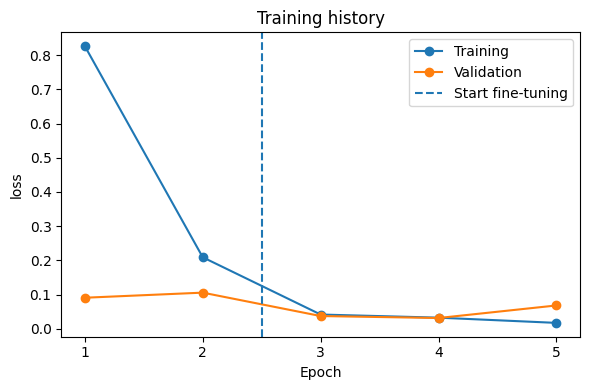

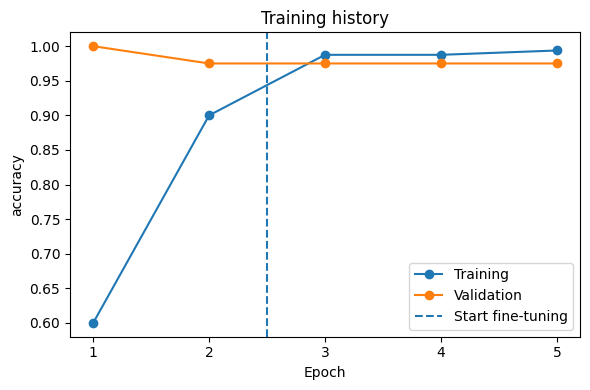

In [ ]:
if MODEL_MODE == "train":
    p_dog_val = model.predict(val_ds, verbose=0).reshape(-1)
    y_true_val = labels[val_idx]
    y_pred_val = (p_dog_val >= 0.5).astype(np.int32)
    matrix = pd.DataFrame(confusion_matrix(y_true_val, y_pred_val, labels=[0, 1]),
                          index=["true_cat", "true_dog"], columns=["pred_cat", "pred_dog"])
    print("検証集合の混同行列（独立最終テストではありません）")
    display(matrix)
    print(classification_report(y_true_val, y_pred_val, labels=[0, 1],
                                target_names=CLASS_NAMES, digits=3, zero_division=0))
    val_results = manifest.iloc[val_idx].copy()
    val_results["p_cat"] = 1.0 - p_dog_val
    val_results["p_dog"] = p_dog_val
    val_results["predicted_class"] = [CLASS_NAMES[i] for i in y_pred_val]
    val_results.to_csv(RUN_DIR / "validation_predictions.csv", index=False, encoding="utf-8-sig")
    matrix.to_csv(RUN_DIR / "validation_confusion_matrix.csv", encoding="utf-8-sig")
    save_json(RUN_DIR / "validation_metrics.json", {
        "accuracy": float(np.mean(y_pred_val == y_true_val)),
        "roc_auc": float(roc_auc_score(y_true_val, p_dog_val)),
        "n": int(len(y_true_val)), "note": "validation set used for model selection"
    })
    for metric in ["loss", "accuracy"]:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(history_df["epoch"], history_df[metric], marker="o", label="Training")
        ax.plot(history_df["epoch"], history_df["val_" + metric], marker="o", label="Validation")
        ax.axvline(HEAD_EPOCHS + 0.5, linestyle="--", label="Start fine-tuning")
        ax.set(xlabel="Epoch", ylabel=metric, title="Training history")
        ax.set_xticks(history_df["epoch"])
        ax.legend()
        fig.tight_layout()
        fig.savefig(RUN_DIR / f"training_{metric}.png", dpi=150)
        plt.show()
        plt.close(fig)
else:
    metrics_file = RUN_DIR / "validation_metrics.json"
    if metrics_file.is_file():
        print("保存済みの検証結果:")
        print(metrics_file.read_text(encoding="utf-8"))

## 7. 共通の予測関数とGrad-CAM
cat=0 / dog=1。`model` の1出力は `P(dog)` です。LIMEには `[1-P(dog), P(dog)]` を返します。
通常の予測・LIME・Grad-CAMすべてで `training=False` とし、Dropout等による推論時の変動を避けます。

犬のGrad-CAMではlogit $z$、猫では $-z$ を対象とします。これは単一Sigmoidの2値分類に合わせた定義であり、猫専用の別出力ニューロンがあるという意味ではありません。
LIMEが近似するのはクラスの確率、Grad-CAMが微分するのは対応するlogitです。対象クラスは同じですが、数値の単位や算出方法は異なります。

Grad-CAMの標準対象層は元コードの追加畳み込み層`my_conv_layer`です。軽量構成では`conv5_block3_out`になります。

In [ ]:
def preprocess_rgb_batch(batch: np.ndarray) -> np.ndarray:
    x = np.array(batch, dtype=np.float32, copy=True)  # LIMEの画像をインプレース変更しない
    if x.ndim != 4 or tuple(x.shape[1:]) != (*IMG_SIZE, 3):
        raise ValueError(f"入力形状は (N, {IMG_SIZE[0]}, {IMG_SIZE[1]}, 3) が必要: {x.shape}")
    if not np.isfinite(x).all() or x.min() < -1e-3 or x.max() > 255.001:
        raise ValueError("前処理前のRGB画像（0～255）を渡してください。")
    return preprocess_input(x)

def predict_proba_rgb(batch: np.ndarray) -> np.ndarray:
    """LIME用: RGB 0..255 -> [P(cat), P(dog)]。前処理はここで1回のみ。"""
    batch = np.asarray(batch)
    if len(batch) == 0:
        return np.empty((0, 2), dtype=np.float32)
    outputs = []
    for start in range(0, len(batch), LIME_BATCH_SIZE):
        x = preprocess_rgb_batch(batch[start:start + LIME_BATCH_SIZE])
        p_dog = np.asarray(model(tf.convert_to_tensor(x), training=False)).reshape(-1)
        outputs.append(np.column_stack([1.0 - p_dog, p_dog]))
    probabilities = np.concatenate(outputs).astype(np.float32)
    if not np.isfinite(probabilities).all():
        raise RuntimeError("予測確率に非有限値があります。")
    if np.any(probabilities < 0) or np.any(probabilities > 1):
        raise RuntimeError("予測確率が[0, 1]の範囲外です。モデルの出力を確認してください。")
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-6)
    return probabilities

layer_name = GRADCAM_LAYER.strip() or (
    "my_conv_layer" if HEAD_STYLE == "original" else "conv5_block3_out"
)
conv_layer = model.get_layer(layer_name)
if len(conv_layer.output.shape) != 4:
    raise ValueError("Grad-CAM対象には空間次元のある4次元出力層を指定してください。")
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[conv_layer.output, model.get_layer("dog_logit").output, model.output]
)
print("Grad-CAM対象層:", layer_name, "出力形状:", conv_layer.output.shape)

def make_gradcam(rgb: np.ndarray, target_index: int) -> dict:
    if target_index not in (0, 1):
        raise ValueError("target_index must be 0 (cat) or 1 (dog)")
    x = tf.convert_to_tensor(preprocess_rgb_batch(rgb[None, ...]), dtype=tf.float32)
    with tf.GradientTape() as tape:
        # 全層凍結モデルでも勾配経路を記録できるよう、入力を明示的にwatchする。
        tape.watch(x)
        features, logits, p_dog = grad_model(x, training=False)
        target_score = logits[:, 0] if target_index == 1 else -logits[:, 0]
    gradients = tape.gradient(target_score, features)
    if gradients is None:
        raise RuntimeError("勾配を取得できません。対象層と出力の計算グラフを確認してください。")
    tf.debugging.assert_all_finite(gradients, "Grad-CAM勾配が非有限値です。")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    signed = tf.reduce_sum(features * weights, axis=-1)[0]
    tf.debugging.assert_all_finite(signed, "Grad-CAMが非有限値です。")
    positive = tf.nn.relu(signed)
    peak = float(tf.reduce_max(positive).numpy())
    native = tf.math.divide_no_nan(positive, tf.reduce_max(positive))
    resized = tf.image.resize(native[None, ..., None], IMG_SIZE, method="bilinear")[0, ..., 0]
    probability = float(p_dog.numpy()[0, 0])
    return {
        "signed_raw": signed.numpy(), "native": native.numpy(),
        "resized": np.clip(resized.numpy(), 0, 1), "positive_peak": peak,
        "empty": peak == 0.0, "target_logit": float(target_score.numpy()[0]),
        "probabilities": np.array([1 - probability, probability], dtype=np.float32),
    }

Grad-CAM対象層: my_conv_layer 出力形状: (None, 7, 7, 1024)


## 8. LIME
LIMEには前処理前のRGB画像を渡します。画像を隠す摂動はRGB空間で行い、変更後の画像を共通モデルで予測します。
乱数シードとSLICの設定を記録します。同じ条件での比較が目的ですが、ライブラリや実行環境を変えた場合の完全一致までは保証しません。

表示する黄色い線は選ばれた領域の境界であり、輪郭の画素自体の寄与度を表す線ではありません。
符号付きの領域係数も別途保存します。局所モデルの重み付きR²と元画像における近似誤差は参考値であり、説明の忠実性を保証するものではありません。
可視化の注意： LIMEの係数推定は正負両方に対して実施します。比較図では正の係数を持つ上位領域のみを着色し、各画像内の最大正係数で0～1に正規化します。弱い正の係数は無色～淡い赤、強い正の係数は濃い赤で示します。未表示の領域は寄与がないとは限りません。


In [ ]:
def explain_lime(rgb: np.ndarray, target_index: int) -> dict:
    segments = slic(
        rgb.astype(np.float32) / 255.0,
        n_segments=LIME_SEGMENTS, compactness=LIME_COMPACTNESS,
        sigma=1.0, start_label=0, channel_axis=-1
    ).astype(np.int32)
    segment_count = int(len(np.unique(segments)))
    explainer = lime_image.LimeImageExplainer(random_state=LIME_SEED)
    explanation = explainer.explain_instance(
        image=rgb.astype(np.double), classifier_fn=predict_proba_rgb,
        labels=(target_index,), top_labels=None,
        hide_color=LIME_HIDE_COLOR,
        num_features=min(LIME_FIT_FEATURES, segment_count),
        num_samples=LIME_SAMPLES, batch_size=LIME_BATCH_SIZE,
        segmentation_fn=lambda image: segments,
        random_seed=LIME_SEED,
    )
    # get_image_and_maskの画像は使わず、正しいRGB画像にmaskを適用する。
    _, mask = explanation.get_image_and_mask(
        target_index, positive_only=True, num_features=LIME_DISPLAY_FEATURES,
        hide_rest=False, min_weight=0.0,
    )
    mask = mask > 0
    weights = {int(i): float(w) for i, w in explanation.local_exp[target_index]}
    weight_map = np.zeros(segments.shape, dtype=np.float32)
    for segment_id, weight in weights.items():
        weight_map[segments == segment_id] = weight
    # 選択された「正の寄与」のみを描画用に抽出する。LIMEの局所近似は改変しない。
    # maskはget_image_and_mask(positive_only=True)の出力（上位の正の領域）。
    positive_weight_map = np.where(mask, np.maximum(weight_map, 0.0), 0.0).astype(np.float32)
    positive_peak = float(np.max(positive_weight_map))
    if positive_peak > 0.0:
        positive_normalized = positive_weight_map / positive_peak
    else:
        positive_normalized = np.zeros_like(positive_weight_map)
    # 0.2.0.1のscore/local_predは単一値。将来の辞書形式にも対応する。
    def value_for_target(value):
        if isinstance(value, dict):
            value = value[target_index]
        return float(np.asarray(value).reshape(-1)[0])
    score = value_for_target(explanation.score)
    local_prediction = value_for_target(explanation.local_pred)
    if not (np.isfinite(score) and np.isfinite(local_prediction)):
        warnings.warn("LIMEの近似診断値が非有限値です。領域分割・サンプル数を確認してください。")
    return {
        "segments": segments, "segment_count": segment_count,
        "mask": mask, "weights": weights, "weight_map": weight_map,
        "positive_weight_map": positive_weight_map,
        "positive_normalized": positive_normalized,
        "positive_peak": positive_peak,
        "score": score, "local_prediction": local_prediction,
        "positive_ids": sorted(int(i) for i in np.unique(segments[mask])),
    }

## 9. 比較図の生成・保存

比較図は 入力画像 / LIME / Grad-CAM の横並びです。

- LIME： 標準の`get_image_and_mask(..., positive_only=True)`が選んだ上位領域の係数を表示します。低い正の係数は透明（元画像のまま）、高い正の係数ほど赤くなります。負の係数と未選択領域は着色しません。係数の推定処理は変更しません。
- Grad-CAM： 従来の`jet`カラーマップのまま、青＝低い、赤＝高い値を示します。
- 表示用の閾値・透明度を変えても、LIME/Grad-CAMの元の計算値は変更されません。両手法の色の濃さを直接数値比較することはできません。
- 説明対象の正負を含む全LIME係数をCSV・NPZに保存します。上位領域の境界線のみの画像`lime_positive_boundaries.png`も保存します。


In [ ]:
def lime_red_overlay(image: np.ndarray, normalized: np.ndarray, mask: np.ndarray,
                     max_alpha: float, threshold: float, gamma: float):
    """選択されたLIMEの正の係数だけ、強度に応じた赤の透明度で重ねる。

    normalized: 選択された正の係数を画像内の最大値で割った0～1のマップ。
    threshold以下では透明（alpha=0）。負の寄与・非選択領域も透明。
    LIMEの係数の推定・順位は変更しない。
    """
    if not (0 <= max_alpha <= 1 and 0 <= threshold < 1 and gamma > 0):
        raise ValueError("LIMEの赤色表示パラメータを確認してください。")
    base = np.asarray(image, dtype=np.float32)
    if base.max() > 1:
        base = base / 255.0
    positive = np.clip(np.asarray(normalized, dtype=np.float32), 0, 1)
    selected = np.asarray(mask, dtype=bool)
    if positive.shape != base.shape[:2] or selected.shape != base.shape[:2]:
        raise ValueError("RGB画像とLIMEの係数マップのサイズが一致しません。")

    relative_strength = np.clip((positive - threshold) / (1.0 - threshold), 0, 1)
    alpha_map = max_alpha * (relative_strength ** gamma) * selected.astype(np.float32)
    alpha = alpha_map[..., None]
    red = np.zeros_like(base)  # RGB=(1,0,0)を重ねる
    red[..., 0] = 1.0
    overlay = np.clip((1.0 - alpha) * base + alpha * red, 0, 1)
    return overlay, alpha_map


def lime_red_legend_cmap(max_alpha: float, threshold: float, gamma: float):
    """白い背景上での『無色→赤』の変化を示す凡例用カラーマップ。"""
    vals = np.linspace(0, 1, 256, dtype=np.float32)
    relative = np.clip((vals - threshold) / (1 - threshold), 0, 1)
    a = max_alpha * (relative ** gamma)
    rgb = np.column_stack([np.ones_like(a), 1 - a, 1 - a])
    return ListedColormap(rgb)


def make_visuals(rgb: np.ndarray, lime_result: dict, cam_result: dict):
    """LIMEは無色→赤。Grad-CAMは従来のjetのまま。"""
    image = rgb.astype(np.float32) / 255.0
    lime_rgb, _ = lime_red_overlay(
        image, lime_result["positive_normalized"], lime_result["mask"],
        max_alpha=LIME_RED_MAX_ALPHA, threshold=LIME_RED_THRESHOLD,
        gamma=LIME_RED_GAMMA
    )

    heat_rgb = plt.get_cmap("jet")(cam_result["resized"])[..., :3]
    overlay = np.clip((1.0 - OVERLAY_ALPHA) * image + OVERLAY_ALPHA * heat_rgb, 0, 1)
    if cam_result["empty"]:
        overlay = image.copy()
    return lime_rgb, heat_rgb, overlay


def finite_or_none(value):
    return float(value) if np.isfinite(value) else None

def compare_image(image_path: str, target: str = "predicted", true_label: Optional[str] = None,
                  allow_used: bool = False, show: bool = True) -> dict:
    if target not in {"predicted", "cat", "dog"}:
        raise ValueError("targetは predicted / cat / dog のいずれかです。")
    if true_label not in {None, "cat", "dog"}:
        raise ValueError("true_labelは None / cat / dog のいずれかです。")
    rgb, image_info = read_rgb(image_path)
    used = manifest[(manifest["path"] == image_info["path"])
                    | (manifest["file_sha256"] == image_info["file_sha256"])
                    | (manifest["pixel_sha256"] == image_info["pixel_sha256"])]
    overlaps = sorted(used["split"].unique().tolist())
    if overlaps and not allow_used:
        raise ValueError("指定画像は学習・検証に使用済みです: " + str(overlaps)
                         + "。最終確認には別画像を指定してください。"
                           "探索目的で表示する場合のみ allow_used=True を指定できます。")
    if overlaps:
        warnings.warn("学習・検証に使用済みの画像です。未使用画像の性能検証ではありません。")

    # 通常推論と両説明で同じ前処理・モデル・クラスを使用する。
    probabilities = predict_proba_rgb(rgb[None, ...])[0]
    predicted_index = int(probabilities[1] >= 0.5)
    target_index = predicted_index if target == "predicted" else CLASS_NAMES.index(target)
    target_name = CLASS_NAMES[target_index]

    # 推論・勾配実行を1回ウォームアップ。処理時間は厳密なベンチマークではない。
    _ = make_gradcam(rgb, target_index)
    start = time.perf_counter()
    cam = make_gradcam(rgb, target_index)
    cam_seconds = time.perf_counter() - start
    np.testing.assert_allclose(probabilities, cam["probabilities"], rtol=1e-4, atol=1e-5)
    start = time.perf_counter()
    lime_result = explain_lime(rgb, target_index)
    lime_seconds = time.perf_counter() - start
    lime_rgb, heat_rgb, overlay = make_visuals(rgb, lime_result, cam)
    _, lime_display_alpha = lime_red_overlay(
        rgb, lime_result["positive_normalized"], lime_result["mask"],
        LIME_RED_MAX_ALPHA, LIME_RED_THRESHOLD, LIME_RED_GAMMA
    )

    if not lime_result["positive_ids"]:
        warnings.warn("LIMEに表示対象となる正の寄与領域がありません。LIME図は元画像のままになります。")
    if cam["empty"]:
        warnings.warn("Grad-CAMに正の活性がありません。重ね合わせは元画像のまま表示します。")

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    safe_stem = "".join(c if c.isalnum() or c in "-_" else "_" for c in Path(image_path).stem)[:70]
    result_dir = RUN_DIR / "explanations" / f"{safe_stem}_{target_name}_{stamp}"
    result_dir.mkdir(parents=True, exist_ok=False)
    Image.fromarray(rgb).save(result_dir / "input_rgb.png")
    selected_labels = np.where(lime_result["mask"], lime_result["segments"] + 1, 0)
    lime_boundary = mark_boundaries(rgb.astype(np.float32) / 255.0, selected_labels,
                                   color=(1, 1, 0), mode="thick")
    for name, array in [("lime_positive", lime_rgb), ("lime_positive_boundaries", lime_boundary),
                        ("gradcam_heatmap", heat_rgb),
                        ("gradcam_overlay", overlay)]:
        Image.fromarray(np.round(np.clip(array, 0, 1) * 255).astype(np.uint8)).save(result_dir / f"{name}.png")
    Image.fromarray((lime_result["mask"] * 255).astype(np.uint8)).save(result_dir / "lime_mask.png")
    Image.fromarray(np.round(lime_display_alpha * 255).astype(np.uint8)).save(
        result_dir / "lime_red_alpha.png"
    )
    np.savez_compressed(
        result_dir / "explanation_arrays.npz", lime_segments=lime_result["segments"],
        lime_weights=lime_result["weight_map"], lime_positive_mask=lime_result["mask"],
        lime_positive_weights=lime_result["positive_weight_map"],
        lime_positive_normalized=lime_result["positive_normalized"],
        lime_display_alpha=lime_display_alpha,
        gradcam_signed_raw=cam["signed_raw"], gradcam_normalized_native=cam["native"],
        gradcam_normalized_resized=cam["resized"]
    )
    table = pd.DataFrame([
        {"segment_id": int(i), "coefficient": lime_result["weights"].get(int(i), 0.0),
         "selected_in_surrogate": int(i) in lime_result["weights"],
         "displayed_positive": int(i) in lime_result["positive_ids"],
         "area_pixels": int(np.count_nonzero(lime_result["segments"] == i))}
        for i in np.unique(lime_result["segments"])
    ])
    table.to_csv(result_dir / "lime_segment_weights.csv", index=False)
    details = {
        "model_file": str(MODEL_FILE), "model_sha256": MODEL_SHA256,
        "image": image_info, "class_names": CLASS_NAMES, "probabilities": probabilities.tolist(),
        "predicted_class": CLASS_NAMES[predicted_index], "explanation_target": target_name,
        "true_label": true_label,
        "correct_if_label_supplied": None if true_label is None else CLASS_NAMES[predicted_index] == true_label,
        "overlap_with_development_data": overlaps,
        "image_size": list(IMG_SIZE), "head_style": HEAD_STYLE,
        "lime": {"score_type": "target probability", "seed": LIME_SEED,
                 "num_samples": LIME_SAMPLES, "batch_size": LIME_BATCH_SIZE,
                 "max_surrogate_features": LIME_FIT_FEATURES, "max_displayed_features": LIME_DISPLAY_FEATURES,
                 "segmentation": "SLIC", "requested_segments": LIME_SEGMENTS,
                 "actual_segments": lime_result["segment_count"], "compactness": LIME_COMPACTNESS,
                 "sigma": 1.0, "hide_color": LIME_HIDE_COLOR,
                 "displayed_positive_segments": lime_result["positive_ids"],
                 "display_mode": "top positive LIME coefficients only; negatives/unselected not colored",
                 "positive_peak": lime_result["positive_peak"],
                 "display_normalization": "positive coefficient / max selected positive coefficient (per image)",
                 "display_color": "red_only_RGB", "red_max_alpha": LIME_RED_MAX_ALPHA,
                 "red_threshold": LIME_RED_THRESHOLD, "red_gamma": LIME_RED_GAMMA,
                 "opacity_mapping": "alpha=max_alpha*clip((normalized-threshold)/(1-threshold),0,1)**gamma",
                 "signed_coefficients_saved": True,
                 "local_weighted_r2": finite_or_none(lime_result["score"]),
                 "local_prediction": finite_or_none(lime_result["local_prediction"]),
                 "absolute_local_error": finite_or_none(abs(lime_result["local_prediction"] - probabilities[target_index])),
                 "elapsed_seconds": lime_seconds},
        "gradcam": {"layer": layer_name, "score_type": "z" if target_index == 1 else "-z",
                    "target_logit": cam["target_logit"], "native_shape": list(cam["native"].shape),
                    "positive_raw_max": cam["positive_peak"], "empty_positive_map": cam["empty"],
                    "normalization": "ReLU then divide by per-image maximum, or zeros if max=0",
                    "colormap": "jet_RGB", "overlay_alpha": OVERLAY_ALPHA, "elapsed_seconds": cam_seconds},
        "timing_note": "Warm-up, loading, saving and plotting excluded; LIME includes SLIC, perturbations and fitting. Not a formal benchmark.",
        "runtime_versions": version_info(),
    }
    save_json(result_dir / "comparison_metadata.json", details)

    # 同一のサイズ・同一の入力画像を使った比較図。
    fig = plt.figure(figsize=(13.5, 4.8))
    title = (f"Prediction: {CLASS_NAMES[predicted_index]} | "
             f"P(cat)={probabilities[0]:.3f}, P(dog)={probabilities[1]:.3f} | "
             f"Explanation target: {target_name}")
    fig.suptitle(title, fontsize=12)
    titles = ["Model input (RGB, 224 x 224)",
              f"LIME: positive top {len(lime_result['positive_ids'])} regions\nlow=transparent, high=red",
              "Grad-CAM (normalized; blue=low, red=high)"]
    if cam["empty"]:
        titles[2] = "Grad-CAM: no positive activation"
    for index, (array, panel_title) in enumerate(zip([rgb, lime_rgb, overlay], titles), 1):
        ax = fig.add_subplot(1, 3, index)
        ax.imshow(array)
        ax.set_title(panel_title, fontsize=10)
        ax.axis("off")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(result_dir / "comparison.png", dpi=180, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

    # LIMEの「無色→赤」を同じ形で再表示する。凡例は白背景上での例示。
    fig, ax = plt.subplots(figsize=(5.3, 4.6))
    ax.imshow(lime_rgb)
    if lime_result["mask"].any() and lime_result["positive_peak"] > 0:
        legend_cmap = lime_red_legend_cmap(
            LIME_RED_MAX_ALPHA, LIME_RED_THRESHOLD, LIME_RED_GAMMA
        )
        scale_artist = plt.cm.ScalarMappable(norm=Normalize(vmin=0, vmax=1),
                                             cmap=legend_cmap)
        scale_artist.set_array([])
        fig.colorbar(scale_artist, ax=ax, fraction=0.046, pad=0.04,
                     label="Normalized positive LIME coefficient (white background scale)")
    else:
        ax.text(0.5, 0.95, "No selected positive LIME region", color="white",
                ha="center", va="top", transform=ax.transAxes,
                bbox=dict(facecolor="black", alpha=0.55))
    ax.set_title("LIME: low=transparent, strong=red")
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(result_dir / "lime_positive_with_scale.png", dpi=160, bbox_inches="tight")
    if show and SHOW_DIAGNOSTICS:
        plt.show()
    plt.close(fig)

    # 別図で色だけに頼らず確認する。LIME係数とGrad-CAMのスケールは異なる。
    diagnostic_specs = [
        ("lime_segments", mark_boundaries(rgb.astype(np.float32) / 255, lime_result["segments"]),
         "LIME segmentation (not attribution)", None, None, None),
        ("lime_signed_weights", lime_result["weight_map"], "LIME: signed local coefficients", "coolwarm",
         -max(float(np.max(np.abs(lime_result["weight_map"]))), 1e-8),
          max(float(np.max(np.abs(lime_result["weight_map"]))), 1e-8)),
        ("gradcam_native", cam["native"], "Grad-CAM: native spatial resolution", "gray", 0, 1),
        ("gradcam_scale", cam["resized"], "Grad-CAM: normalized intensity", "jet", 0, 1),
    ]
    for name, array, panel_title, cmap, vmin, vmax in diagnostic_specs:
        fig, ax = plt.subplots(figsize=(4.8, 4.1))
        artist = ax.imshow(array, cmap=cmap, vmin=vmin, vmax=vmax,
                           interpolation="nearest" if name == "gradcam_native" else "none")
        ax.set_title(panel_title, fontsize=10)
        ax.axis("off")
        if array.ndim == 2:
            fig.colorbar(artist, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        fig.savefig(result_dir / f"{name}.png", dpi=160, bbox_inches="tight")
        if show and SHOW_DIAGNOSTICS:
            plt.show()
        plt.close(fig)
    print(f"LIME局所近似: 重み付きR²={lime_result['score']:.3f}, "
          f"元画像での確率の近似誤差={abs(lime_result['local_prediction'] - probabilities[target_index]):.4f}")
    print(f"参考処理時間: LIME {lime_seconds:.2f}s / Grad-CAM {cam_seconds:.3f}s")
    print("保存先:", result_dir)
    return {"directory": str(result_dir), "metadata": details}

## 10. Drive上の画像をパスで指定して比較する
ここに最終確認したい画像のフルパスを入力してください。
例：`/content/drive/MyDrive/image_test/test_0.jpg`

`TARGET_CLASS="predicted"` は予測クラスを両手法で説明します。`cat` / `dog` を選ぶと、予測と異なるクラスも指定できます。
`TRUE_LABEL` は正解が分かるときだけ記入します。少数画像の可視化だけでモデル全体の精度や説明の忠実性を評価することはできません。

  0%|          | 0/2000 [00:00<?, ?it/s]

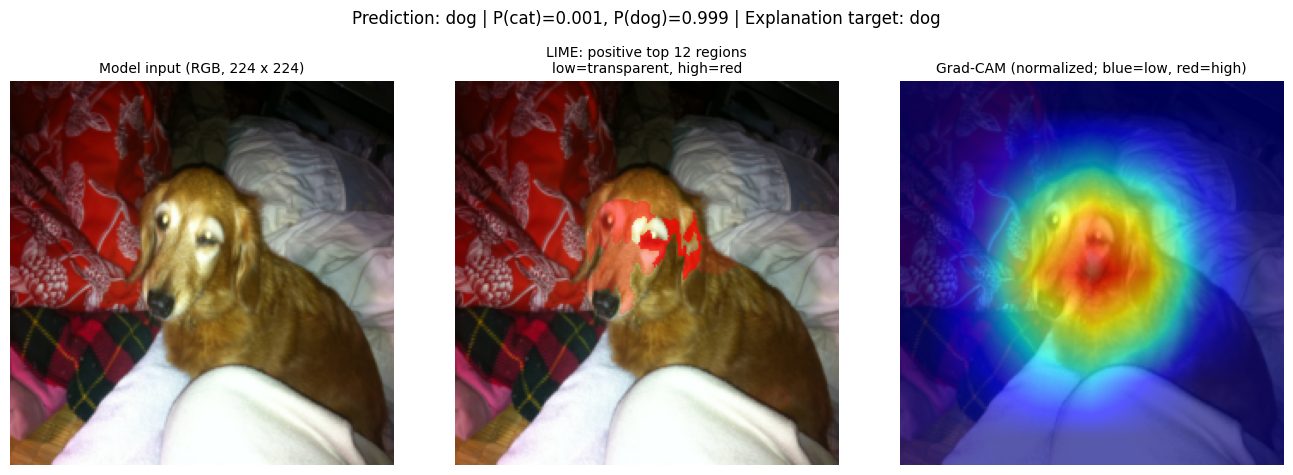

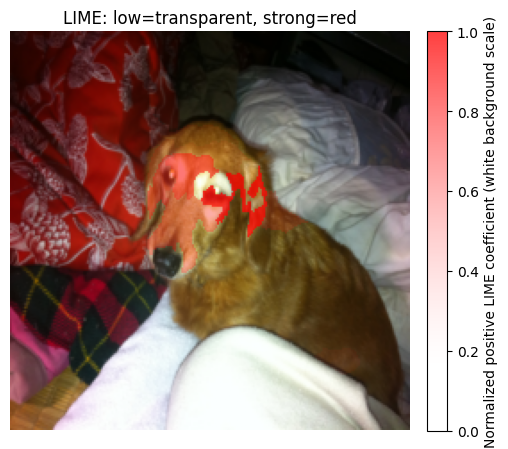

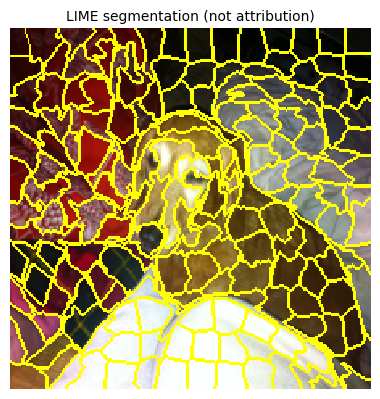

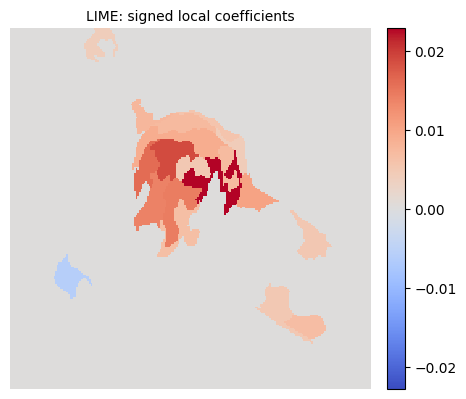

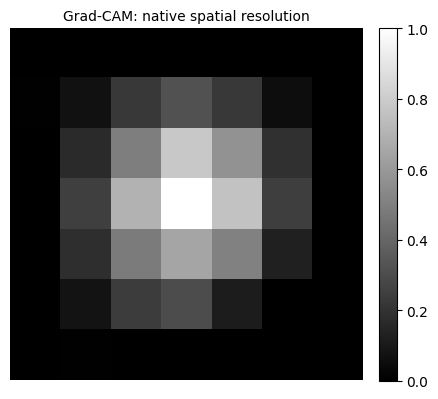

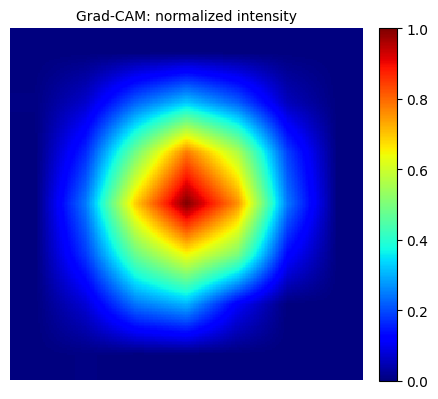

LIME局所近似: 重み付きR²=0.259, 元画像での確率の近似誤差=0.0578
参考処理時間: LIME 34.75s / Grad-CAM 0.710s
保存先: /content/drive/MyDrive/ResNet50_XAI_results/run_20261102T005551_190315Z/explanations/test_8_dog_20261102T011345_878704Z


In [ ]:
TEST_IMAGE_PATH = "/content/drive/MyDrive/image_test/test_8.jpg"  # @param {type:"string"}
TARGET_CLASS = "dog"  # @param ["predicted", "cat", "dog"]
TRUE_LABEL = "dog"  # @param ["", "cat", "dog"]
ALLOW_USED_IMAGE = False  # @param {type:"boolean"}

if TEST_IMAGE_PATH.strip():
    last_result = compare_image(
        TEST_IMAGE_PATH.strip(), target=TARGET_CLASS,
        true_label=TRUE_LABEL or None, allow_used=ALLOW_USED_IMAGE
    )
else:
    print("TEST_IMAGE_PATHにDrive上の画像パスを入力し、このセルを再実行してください。")

## 11. 任意：Driveのフォルダ内から画像を選択する
`TEST_IMAGE_DIR` を指定して、このセルを実行します。
画像・説明対象を選び、「LIME / Grad-CAMを生成」を押します。選択だけではLIMEを再計算しません。

In [ ]:
TEST_IMAGE_DIR = "/content/drive/MyDrive/image_test"  # @param {type:"string"}

folder = Path(TEST_IMAGE_DIR).expanduser()
if folder.is_dir():
    import ipywidgets as widgets
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
    candidates = sorted(p for p in folder.rglob("*") if p.is_file()
                        and p.suffix.lower() in IMAGE_EXTENSIONS
                        and not any(part.startswith(".") for part in p.relative_to(folder).parts))
    if candidates:
        chooser = widgets.Dropdown(options=[(str(p.relative_to(folder)), str(p)) for p in candidates],
                                   description="画像:", layout=widgets.Layout(width="90%"))
        target_chooser = widgets.Dropdown(options=[("予測クラス", "predicted"), ("猫", "cat"), ("犬", "dog")],
                                          description="説明対象:")
        generate_button = widgets.Button(description="LIME / Grad-CAMを生成", layout=widgets.Layout(width="230px"))
        result_output = widgets.Output()
        def on_generate_clicked(_):
            generate_button.disabled = True
            try:
                with result_output:
                    clear_output(wait=True)
                    print("同一モデル・同一画像で計算中:", chooser.value)
                    globals()["last_result"] = compare_image(chooser.value, target=target_chooser.value)
            except Exception as exc:
                with result_output:
                    print(f"{type(exc).__name__}: {exc}")
            finally:
                generate_button.disabled = False
        generate_button.on_click(on_generate_clicked)
        display(widgets.VBox([chooser, target_chooser, generate_button, result_output]))
    else:
        print("対象フォルダに対応形式の画像がありません。")
else:
    print("TEST_IMAGE_DIRを実在する画像フォルダに変更するか、第10節のパス指定を使用してください。")

## 12. 任意：複数画像をまとめて処理する
パスのリストを設定すると、同じ学習済みモデルで順に比較図を作成します。
画像ごとにLIMEを計算するため、最初は第10節で1枚の結果を確認してください。
`BATCH_IMAGE_PATHS` が空のままなら何もしません。正解ラベルはこのセルでは収集しません。

In [ ]:
BATCH_IMAGE_PATHS = [
    # "/content/drive/MyDrive/image_test/test_8.jpg",
    # "/content/drive/MyDrive/image_test/test_cat.jpg",
]

batch_summary = []
for path in BATCH_IMAGE_PATHS:
    result = compare_image(path, target="predicted", show=False)
    info = result["metadata"]
    batch_summary.append({
        "path": path, "prediction": info["predicted_class"],
        "p_cat": info["probabilities"][0], "p_dog": info["probabilities"][1],
        "explanation_target": info["explanation_target"], "result_dir": result["directory"]
    })
if batch_summary:
    summary = pd.DataFrame(batch_summary)
    display(summary)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    summary.to_csv(RUN_DIR / f"batch_summary_{stamp}.csv", index=False, encoding="utf-8-sig")

## 出力を読むときの注意

今回のLIME比較図は「上位の正の係数」を無色～赤で示したものです。弱い係数は表示しませんが、寄与がゼロと断定できるわけではありません。

LIMEは、画像を領域に分けて隠したときの予測を局所的なモデルで近似します。領域の分割・隠し方・サンプル数・乱数で結果が変わります。
黄色い境界線を「その輪郭画素の寄与度」と読まないでください。無色部分には、係数の小さい正領域、負の係数、局所近似モデルに採用されなかった領域などが混在します。無色＝寄与ゼロではありません。
`lime_segment_weights.csv` の `selected_in_surrogate=False` の領域は、局所モデルに選択されなかった領域です。

Grad-CAMは、対象層の粗い特徴マップから作ります。標準の224×224入力では通常7×7のマップを拡大するため、ぼんやりすること自体は異常ではありません。
`gradcam_native.png` は拡大前の解像度、`gradcam_scale.png` は色と数値の対応を確認するための図です。
ReLUで負の値を除くため、青い部分や0の部分を「そのクラスに反対する証拠」とは解釈しません。

両手法が似た場所を示しても忠実性が保証されるわけではなく、異なる場所を示しても直ちに実装不良とはいえません。
原画像の分類結果、対象クラス、Grad-CAMの対象層、LIMEの近似診断・分割を合わせて確認してください。
独立したテスト集合での性能評価や、領域を変えたときの予測変化による検証は、この見た目の比較とは別の評価です。

### 再利用
出力された `model.keras`、`run_config.json`、`data_manifest.csv` を同じフォルダに保管してください。
次回は第2節で `MODEL_MODE="load"` と保存モデルのパスを指定すれば、学習せず比較できます。
同じモデル・同じ画像を使った証拠として、モデルと入力ファイルのSHA256もJSONに記録します。

## 13. 任意：保存済みのLIME結果を赤色だけで再表示

一度生成済みの`explanation_arrays.npz`を使い、モデルを再学習せず、LIMEも再計算せず、表示だけを変えられます。

- `LIME_REDISPLAY_ALPHA`：赤の最大不透明度（0～1）。
- `LIME_REDISPLAY_THRESHOLD`：選択された正係数の正規化値がこの値以下なら無色（0～1未満）。
- `LIME_REDISPLAY_GAMMA`：1より大きいと弱い領域を抑えます。

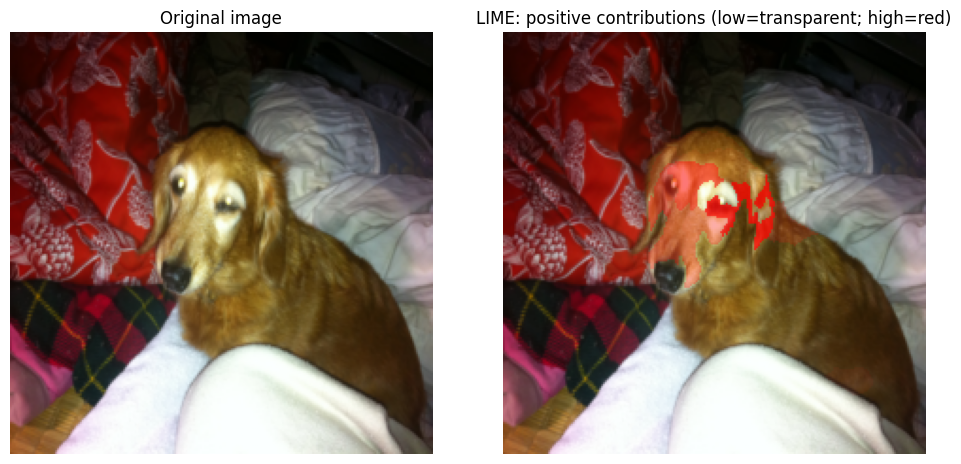

保存先: /content/drive/MyDrive/ResNet50_XAI_results/run_20261102T005551_190315Z/explanations/test_8_dog_20261102T011345_878704Z/lime_red_alpha0.75_threshold0.15_gamma1.50.png


In [ ]:
LIME_REDISPLAY_DIR = ""   # @param {type:"string"}
LIME_REDISPLAY_ALPHA = 0.75  # @param {type:"number"}
LIME_REDISPLAY_THRESHOLD = 0.15  # @param {type:"number"}
LIME_REDISPLAY_GAMMA = 1.5  # @param {type:"number"}

if LIME_REDISPLAY_DIR.strip():
    previous_dir = Path(LIME_REDISPLAY_DIR.strip())
elif "last_result" in globals():
    previous_dir = Path(last_result["directory"])
else:
    raise ValueError("第10節または第11節で一度比較するか、LIME_REDISPLAY_DIRを指定してください。")

previous_rgb = np.asarray(Image.open(previous_dir / "input_rgb.png").convert("RGB"), dtype=np.float32) / 255.0
with np.load(previous_dir / "explanation_arrays.npz") as saved:
    old_signed = saved["lime_weights"]
    old_mask = saved["lime_positive_mask"].astype(bool)

old_positive = np.where(old_mask, np.maximum(old_signed, 0.0), 0.0)
peak = float(old_positive.max())
old_normalized = old_positive / peak if peak > 0 else np.zeros_like(old_positive)
new_overlay, new_alpha = lime_red_overlay(
    previous_rgb, old_normalized, old_mask,
    max_alpha=LIME_REDISPLAY_ALPHA,
    threshold=LIME_REDISPLAY_THRESHOLD,
    gamma=LIME_REDISPLAY_GAMMA
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.7))
axes[0].imshow(previous_rgb)
axes[0].set_title("Original image")
axes[1].imshow(new_overlay)
axes[1].set_title("LIME: positive contributions (low=transparent; high=red)")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
filename = previous_dir / (
    f"lime_red_alpha{LIME_REDISPLAY_ALPHA:.2f}_threshold{LIME_REDISPLAY_THRESHOLD:.2f}_"
    f"gamma{LIME_REDISPLAY_GAMMA:.2f}.png"
)
Image.fromarray(np.round(new_overlay * 255).astype(np.uint8)).save(filename)
plt.show()
plt.close(fig)
print("保存先:", filename)
